<a href="https://colab.research.google.com/github/Prathama-1/Quant-Research/blob/main/Quant_research.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import glob, importlib.util, os, sys, zipfile
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

IN_COLAB = os.path.isdir('/content')
WORK = '/content/qr' if IN_COLAB else '.'
os.makedirs(WORK, exist_ok=True)


def find(name):
    for folder, _, names in os.walk(WORK):
        if name in names:
            return os.path.join(folder, name)
    return None


NEEDED = ['harness_public.py', 'task1.py', 'task2.py', 'nifty50_15min_train_2017-04-03_2022-01-31.csv']
if IN_COLAB:
    zips = glob.glob('/content/*.zip')
    print('Zips found:', [os.path.basename(p) for p in zips])
    for path in zips:
        with zipfile.ZipFile(path) as z:
            z.extractall(os.path.join(WORK, os.path.splitext(os.path.basename(path))[0]))
missing = [n for n in NEEDED if not find(n)]
print('Missing, check both zips are in /content:' if missing else 'All files found.', missing or '')


def load(name):
    path = find(name + '.py')
    spec = importlib.util.spec_from_file_location(name, path)
    m = importlib.util.module_from_spec(spec)
    sys.modules[name] = m
    spec.loader.exec_module(m)
    return m


H, T1, T2 = load('harness_public'), load('task1'), load('task2')
BARS_CSV = find('nifty50_15min_train_2017-04-03_2022-01-31.csv')
EXP_CSV = find('nifty_monthly_expiries_2017-01_2022-01.csv')
STOCK_CSV = find('stocks_daily_train_2021-04-26_2024-06-30.csv')
NIFTY_CSV = find('nifty50_daily_2021-04-26_2024-06-30.csv')

Zips found: ['Prathama_Bharadwaj.zip', 'candidate_pack.zip']
All files found. 


In [3]:
BLUE, ORANGE, AQUA, GREY = '#2a78d6', '#eb6834', '#1baf7a', '#898781'
plt.rcParams.update({'figure.figsize': (10, 4), 'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.edgecolor': '#c3c2b7', 'axes.grid': True, 'axes.grid.axis': 'y', 'grid.color': '#e1e0d9', 'grid.linewidth': .6,
                     'axes.axisbelow': True, 'legend.frameon': False, 'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left'})


def bar_labels(ax, xs, ys, fmt='%.1f'):
    """Write each bar's value just outside its end."""
    for x, y in zip(xs, ys):
        ax.annotate(fmt % y, (x, y), xytext=(0, 3 if y >= 0 else -3), textcoords='offset points', ha='center', va='bottom' if y >= 0 else 'top', fontsize=9, color='#52514e')


def end_label(ax, s, fmt='x%.2f'):
    """Label a line at its last point."""
    ax.annotate(fmt % s.iloc[-1], (s.index[-1], s.iloc[-1]), xytext=(4, 0), textcoords='offset points', va='center', fontsize=9, color='#52514e')


def years_axis(ax):
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))


def perf(r, rf=0.0):
    """Sharpe, worst loss and yearly return from a daily return series."""
    eq = (1 + r).cumprod()
    return dict(sharpe=(r.mean() - rf / 252) / r.std() * 252 ** .5, dd=(eq / eq.cummax() - 1).min(), cagr=eq.iloc[-1] ** (252 / len(r)) - 1)


In [4]:
# %%
# =========================================================================================================
# TASK 1: NIFTY
# =========================================================================================================
# 1.0 LOAD. Builds one row per day, and one row per 14:30 decision, using the same rules as task1.py.
bars = H.load_bars(BARS_CSV)
ex = H.load_expiries(EXP_CSV)
raw = pd.read_csv(BARS_CSV, parse_dates=['datetime'])
nd = pd.read_csv(NIFTY_CSV, parse_dates=['date']).set_index('date').sort_index()

g = bars.groupby(bars.index.normalize())
day = pd.DataFrame({'open': g.open.first(), 'close': g.close.last()})
day['gap'] = day.open / day.close.shift() - 1
day['session'] = day.close / day.open - 1

o, c = bars.open.values, bars.close.values
tod = np.asarray(bars.index.hour * 60 + bars.index.minute)
stamp = np.asarray(bars.index.normalize())
is_first = np.r_[True, stamp[1:] != stamp[:-1]]
day_id = np.cumsum(is_first) - 1
first = np.flatnonzero(is_first)
so_far = np.arange(len(c)) - first[day_id] + 1

P1 = T1.PARAMS
dec = np.flatnonzero((tod == 14 * 60 + 30) & (so_far >= T1.MIN_SESSION_BARS))
px = pd.Series(c[dec])
nights = pd.DataFrame(index=bars.index[dec].normalize())
nights['above_ma'] = (px > px.shift(1).rolling(P1['ma_days'], min_periods=P1['ma_days'] // 2).mean()).values
nights['so_far'] = c[dec] / o[first[day_id[dec]]] - 1
nights['vol'] = px.pct_change().rolling(T1.VOL_DAYS, min_periods=5).std().fillna(0).values * 252 ** .5
nxt = np.searchsorted(first, dec, side='right')
ok = nxt < len(first)
nights['gap_next'] = np.nan
nights.loc[nights.index[ok], 'gap_next'] = o[first[nxt[ok]]] / c[first[nxt[ok]] - 1] - 1
nights['paper'] = np.nan
nights.loc[nights.index[ok], 'paper'] = o[first[nxt[ok]]] / o[dec[ok] + 1] - 1
nights['weak_ok'] = nights.so_far >= P1['session_floor']
nights['vol_ok'] = nights.vol < P1['vol_cap']
nights['raw'] = nights.above_ma & nights.weak_ok & nights.vol_ok
print(len(bars), 'bars,', len(day), 'days,', len(nights), 'decisions')

29803 bars, 1193 days, 1192 decisions


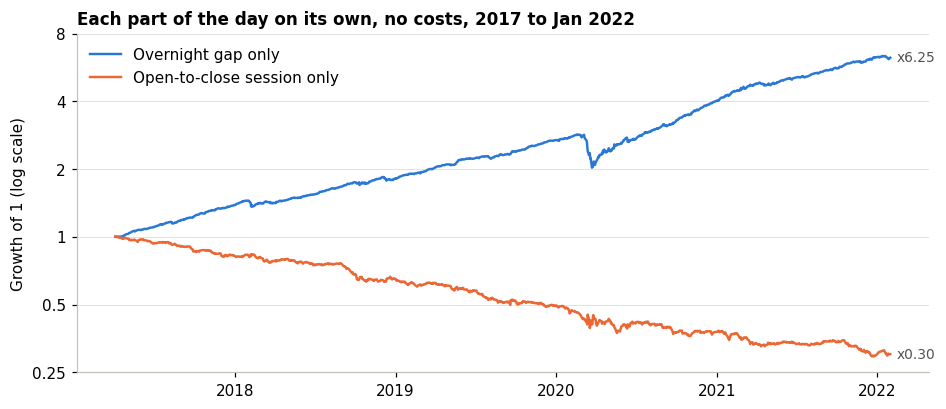

Overnight  mean  15.64 bps | Sharpe  3.45 | t  7.50 | up 72.7% of days
Session    mean  -9.59 bps | Sharpe -1.57 | t -3.42 | up 46.6% of days


In [5]:
# %%
# 1.1 INSIGHT: All of Nifty's return arrives while the market is shut.
# Holding only the overnight gap, against holding only the open-to-close session. Before any costs.
on = (1 + day.gap.fillna(0)).cumprod()
se = (1 + day.session).cumprod()
fig, ax = plt.subplots()
ax.plot(on.index, on.values, color=BLUE, lw=1.6, label='Overnight gap only')
ax.plot(se.index, se.values, color=ORANGE, lw=1.6, label='Open-to-close session only')
ax.set_yscale('log'); ax.set_yticks([.25, .5, 1, 2, 4, 8]); ax.set_yticklabels(['0.25', '0.5', '1', '2', '4', '8']); ax.minorticks_off()
end_label(ax, on); end_label(ax, se); years_axis(ax); ax.legend(loc='upper left')
ax.set_ylabel('Growth of 1 (log scale)'); ax.set_title('Each part of the day on its own, no costs, 2017 to Jan 2022')
plt.show()
for name, s in [('Overnight', day.gap.dropna()), ('Session', day.session)]:
    print('%-10s mean %6.2f bps | Sharpe %5.2f | t %5.2f | up %.1f%% of days' % (name, s.mean() * 1e4, s.mean() / s.std() * 252 ** .5, s.mean() / s.std() * len(s) ** .5, 100 * (s > 0).mean()))


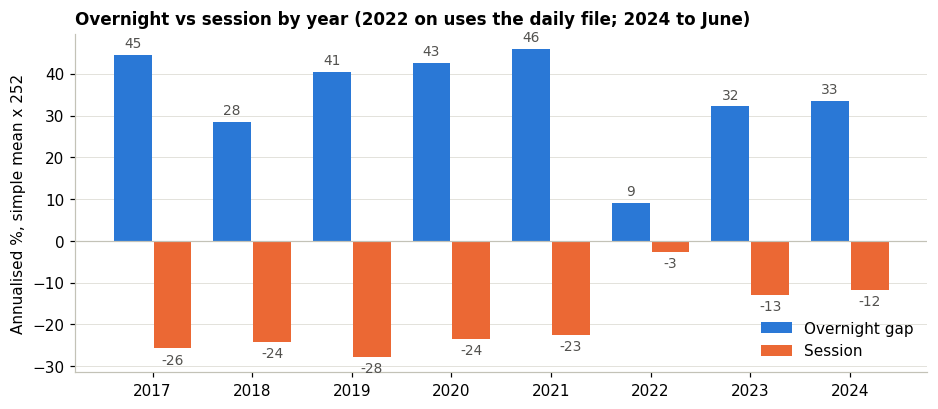

After Jan 2022, Gap      mean   9.37 bps | Sharpe  2.63
After Jan 2022, Session  mean  -3.49 bps | Sharpe -0.78


In [6]:
# %%
# 1.2 INSIGHT: The pattern holds every full year, and continues in the daily file after the 15-minute data ends, though smaller.
nd['gap'] = nd.open / nd.close.shift() - 1
nd['session'] = nd.close / nd.open - 1
later = nd[nd.index > day.index[-1]]
early = day[day.index.year <= 2021]
tab = pd.concat([early.groupby(early.index.year)[['gap', 'session']].mean(), later.groupby(later.index.year)[['gap', 'session']].mean()]) * 25200
x = np.arange(len(tab))
fig, ax = plt.subplots()
ax.bar(x - .2, tab.gap, .38, color=BLUE, label='Overnight gap')
ax.bar(x + .2, tab.session, .38, color=ORANGE, label='Session')
bar_labels(ax, x - .2, tab.gap, '%.0f'); bar_labels(ax, x + .2, tab.session, '%.0f')
ax.axhline(0, color='#c3c2b7', lw=.8); ax.set_xticks(x); ax.set_xticklabels(tab.index); ax.legend()
ax.set_ylabel('Annualised %, simple mean x 252'); ax.set_title('Overnight vs session by year (2022 on uses the daily file; 2024 to June)')
plt.show()
for name, s in [('Gap', later.gap.dropna()), ('Session', later.session)]:
    print('After Jan 2022, %-8s mean %6.2f bps | Sharpe %5.2f' % (name, s.mean() * 1e4, s.mean() / s.std() * 252 ** .5))


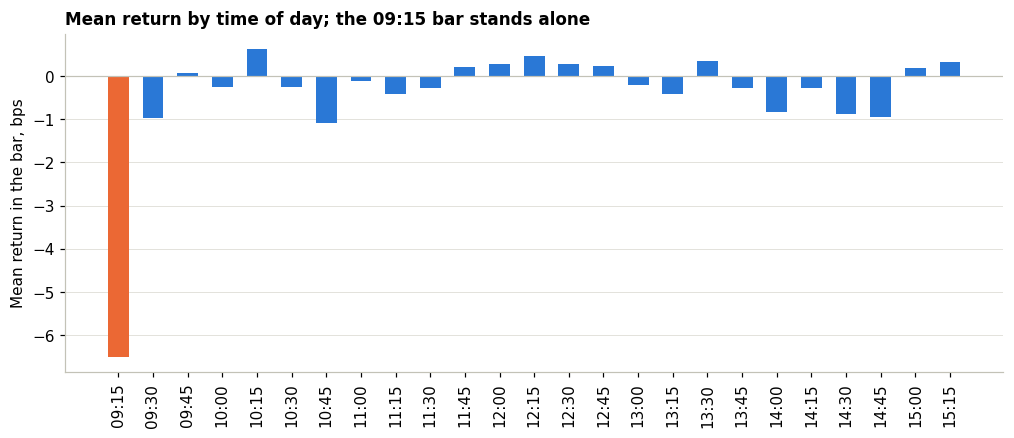

09:15 bar by year, bps: {2017: -6.17, 2018: -5.31, 2019: -7.04, 2020: -10.02, 2021: -3.98, 2022: -4.49}


In [7]:
# %%
# 1.3 INSIGHT: The first bar gives back a large part of the gap. This is why a fill delay on a morning exit hurts.
rb = bars[np.isin(day_id, np.flatnonzero(np.bincount(day_id) == 25))]
rb = (rb.close / rb.open - 1).groupby(rb.index.strftime('%H:%M')).mean() * 1e4
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(range(len(rb)), rb.values, .6, color=[ORANGE if i == 0 else BLUE for i in range(len(rb))])
ax.axhline(0, color='#c3c2b7', lw=.8); ax.set_xticks(range(len(rb))); ax.set_xticklabels(rb.index, rotation=90)
ax.set_ylabel('Mean return in the bar, bps'); ax.set_title('Mean return by time of day; the 09:15 bar stands alone')
plt.show()
fb = bars[tod == 9 * 60 + 15]
yr = (fb.close / fb.open - 1).groupby(fb.index.year).mean() * 1e4
print('09:15 bar by year, bps:', yr.round(2).to_dict())

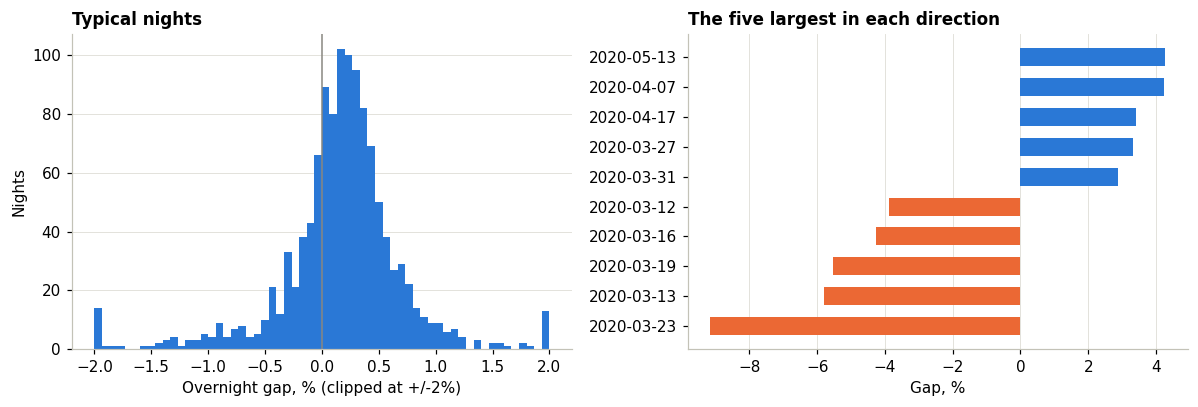

Mean 15.6 bps, median 20.0 bps, 72.7% of nights up


In [8]:
# %%
# 1.4 INSIGHT: Most nights gap up, but the worst nights are far larger than the best. The tail is why filters are needed.
gp = day.gap.dropna() * 100
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].hist(gp.clip(-2, 2), bins=60, color=BLUE)
ax[0].axvline(0, color=GREY, lw=1); ax[0].set_xlabel('Overnight gap, % (clipped at +/-2%)'); ax[0].set_ylabel('Nights'); ax[0].set_title('Typical nights')
big = pd.concat([gp.nsmallest(5), gp.nlargest(5)]).sort_values()
ax[1].barh([str(d.date()) for d in big.index], big.values, .6, color=[ORANGE if v < 0 else BLUE for v in big.values])
ax[1].set_xlabel('Gap, %'); ax[1].grid(axis='x', color='#e1e0d9'); ax[1].grid(axis='y', visible=False); ax[1].set_title('The five largest in each direction')
plt.tight_layout(); plt.show()
print('Mean %.1f bps, median %.1f bps, %.1f%% of nights up' % (gp.mean() * 100, gp.median() * 100, (gp > 0).mean() * 100))


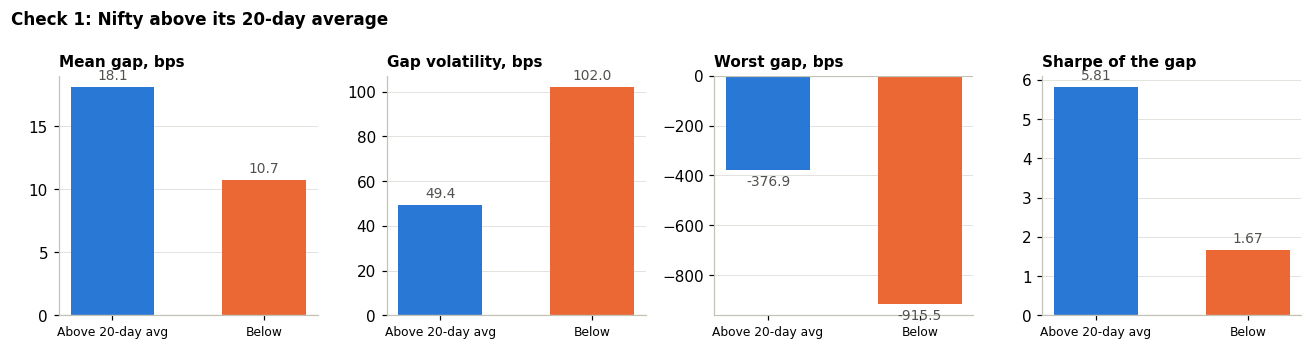

Above 20-day avg: 782 nights | Below: 409 nights


In [11]:
# %%
# 1.5 HOW EACH OF THE FOUR CHECKS SPLITS THE NIGHTS. Each check is tested alone, on all nights.
def check_chart(mask, yes, no, title):
    a, b = nights.gap_next[mask].dropna() * 1e4, nights.gap_next[~mask].dropna() * 1e4
    rows = [('Mean gap, bps', a.mean(), b.mean()), ('Gap volatility, bps', a.std(), b.std()), ('Worst gap, bps', a.min(), b.min())]
    fig, ax = plt.subplots(1, 4, figsize=(12, 3.2))
    for i, (lab, u, v) in enumerate(rows):
        ax[i].bar([0, 1], [u, v], .55, color=[BLUE, ORANGE]); bar_labels(ax[i], [0, 1], [u, v]); ax[i].set_xticks([0, 1]); ax[i].set_xticklabels([yes, no], fontsize=8)
        ax[i].axhline(0, color='#c3c2b7', lw=.8); ax[i].set_title(lab, fontsize=10)
    sh = [a.mean() / a.std() * 252 ** .5, b.mean() / b.std() * 252 ** .5]
    ax[3].bar([0, 1], sh, .55, color=[BLUE, ORANGE]); bar_labels(ax[3], [0, 1], sh, '%.2f'); ax[3].set_xticks([0, 1]); ax[3].set_xticklabels([yes, no], fontsize=8)
    ax[3].axhline(0, color='#c3c2b7', lw=.8); ax[3].set_title('Sharpe of the gap', fontsize=10)
    fig.suptitle(title, x=.01, ha='left', fontsize=11, fontweight='bold'); plt.tight_layout(); plt.show()
    print('%s: %d nights | %s: %d nights' % (yes, len(a), no, len(b)))


check_chart(nights.above_ma, 'Above 20-day avg', 'Below', 'Check 1: Nifty above its 20-day average')

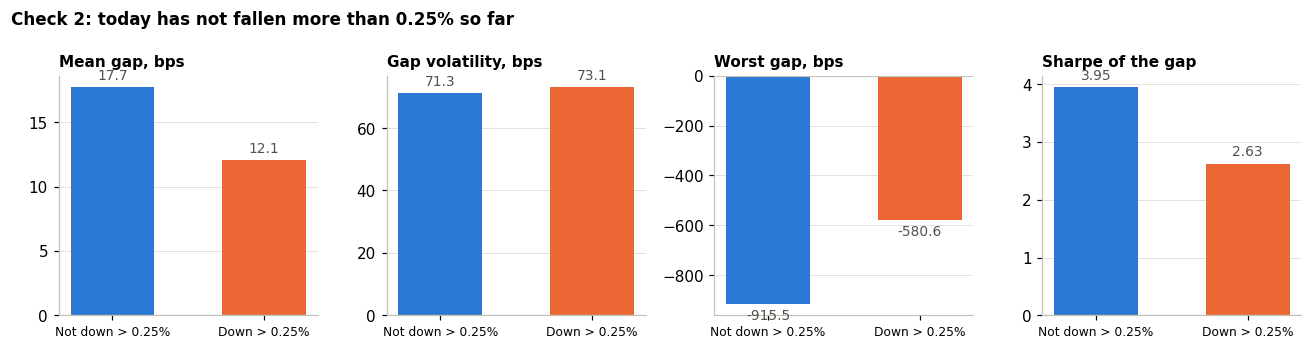

Not down > 0.25%: 733 nights | Down > 0.25%: 458 nights


In [12]:
check_chart(nights.weak_ok, 'Not down > 0.25%', 'Down > 0.25%', 'Check 2: today has not fallen more than 0.25% so far')


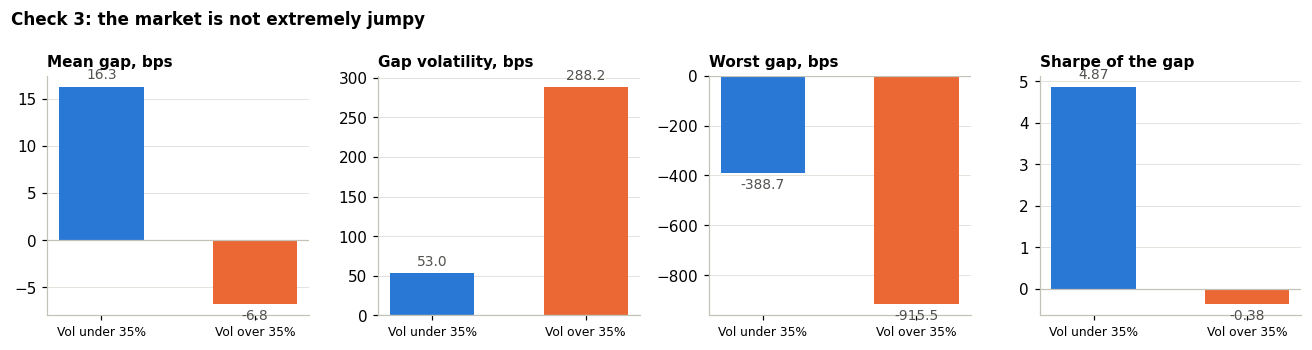

Vol under 35%: 1155 nights | Vol over 35%: 36 nights


In [13]:
check_chart(nights.vol_ok, 'Vol under 35%', 'Vol over 35%', 'Check 3: the market is not extremely jumpy')


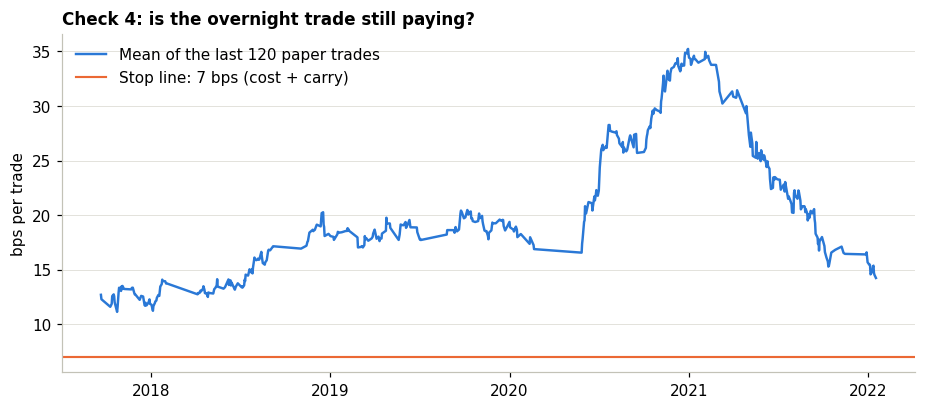

Lowest value 11.1 bps. Nights the gate would have blocked: 0


In [14]:
# %%
# 1.6 CHECK 4: Do recent paper trades still cover costs? The strategy stops if the line falls under the 7 bps cost line.
k = P1['gate_nights']
pp = nights.paper[nights.raw].dropna() * 1e4
roll = pp.rolling(k, min_periods=k // 2).mean().shift(1)
fig, ax = plt.subplots()
ax.plot(roll.index, roll.values, color=BLUE, lw=1.6, label='Mean of the last %d paper trades' % k)
ax.axhline(P1['gate_bps'], color=ORANGE, lw=1.4, label='Stop line: %g bps (cost + carry)' % P1['gate_bps'])
years_axis(ax); ax.legend(); ax.set_ylabel('bps per trade'); ax.set_title('Check 4: is the overnight trade still paying?')
plt.show()
print('Lowest value %.1f bps. Nights the gate would have blocked: %d' % (roll.min(), (roll < P1['gate_bps']).sum()))


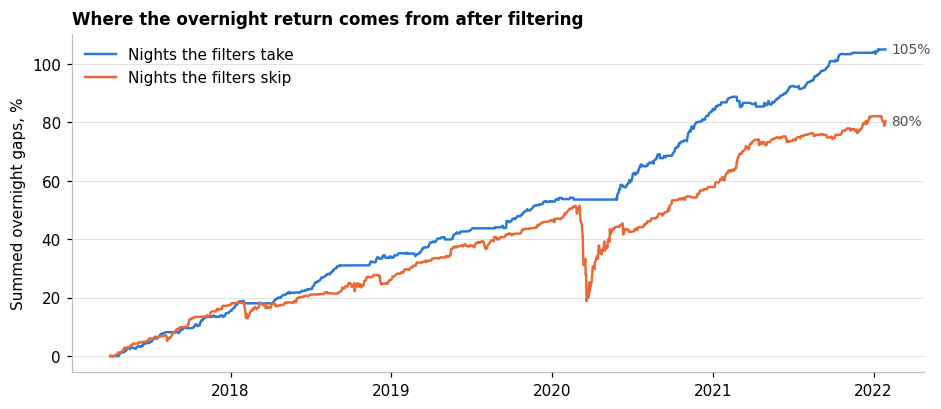

Taken     533 nights | mean  19.69 bps | worst  -1.45% | Sharpe  7.73
Skipped   658 nights | mean  12.23 bps | worst  -9.15% | Sharpe  2.16


In [15]:
# %%
# 1.7 INSIGHT: What the filters do when combined. Nights taken against nights skipped, gaps only, before costs.
n2 = nights.dropna(subset=['gap_next'])
taken = n2.gap_next.where(n2.raw, 0).cumsum() * 100
skipped = n2.gap_next.where(~n2.raw, 0).cumsum() * 100
fig, ax = plt.subplots()
ax.plot(taken.index, taken.values, color=BLUE, lw=1.6, label='Nights the filters take')
ax.plot(skipped.index, skipped.values, color=ORANGE, lw=1.6, label='Nights the filters skip')
end_label(ax, taken, '%.0f%%'); end_label(ax, skipped, '%.0f%%'); years_axis(ax); ax.legend()
ax.set_ylabel('Summed overnight gaps, %'); ax.set_title('Where the overnight return comes from after filtering')
plt.show()
for nm, s in [('Taken', n2.gap_next[n2.raw]), ('Skipped', n2.gap_next[~n2.raw])]:
    print('%-8s %4d nights | mean %6.2f bps | worst %6.2f%% | Sharpe %5.2f' % (nm, len(s), s.mean() * 1e4, s.min() * 100, s.mean() / s.std() * 252 ** .5))


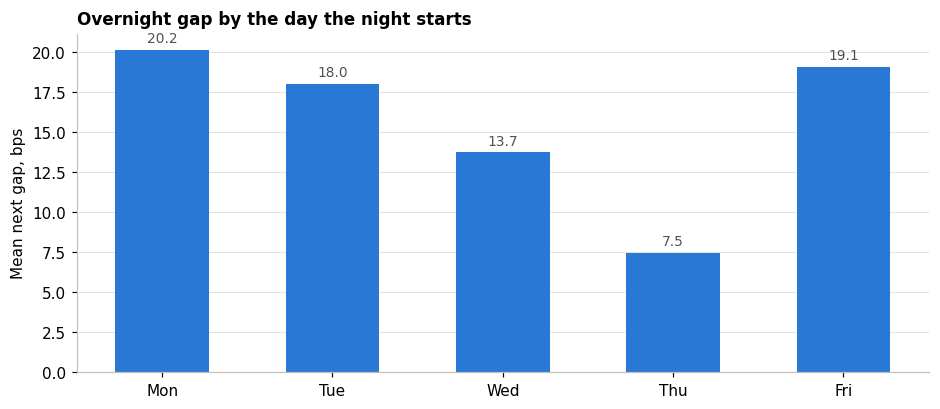

In [16]:
# %%
# 1.8 INSIGHT: Thursday night has the lowest premium. Not used in the strategy, because expiry day changes from Sep 2025.
wk = (day.gap.shift(-1).groupby(day.index.dayofweek).mean() * 1e4).reindex(range(5))
fig, ax = plt.subplots()
ax.bar(range(5), wk.values, .55, color=BLUE); bar_labels(ax, range(5), wk.values)
ax.set_xticks(range(5)); ax.set_xticklabels(['Mon', 'Tue', 'Wed', 'Thu', 'Fri']); ax.set_ylabel('Mean next gap, bps'); ax.set_title('Overnight gap by the day the night starts')
plt.show()

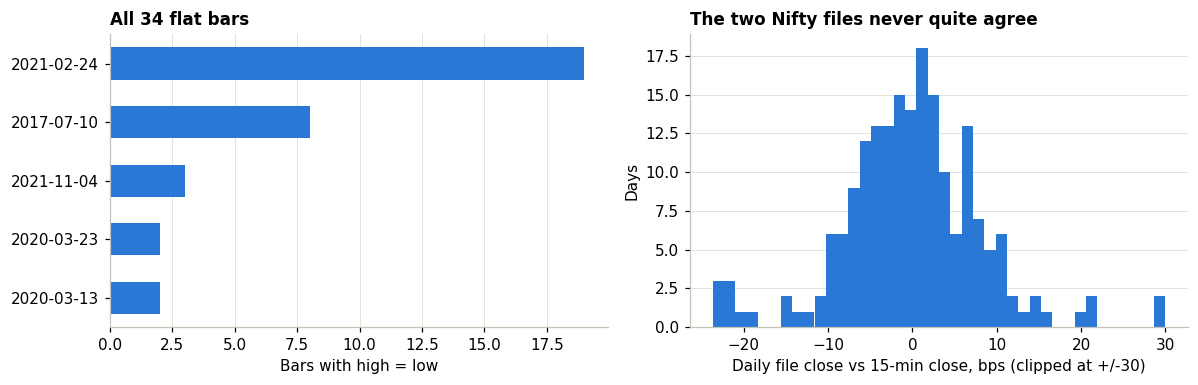

           datetime    open    high     low   close  n_1min
2021-11-04 14:45:00 17829.2 17829.2 17829.2 17829.2      13
2021-11-04 15:00:00 17829.2 17829.2 17829.2 17829.2      15
2021-11-04 15:15:00 17829.2 17829.2 17829.2 17829.2      15
Same day in the daily file: {'open': 17935.05, 'high': 17947.55, 'low': 17900.59, 'close': 17916.8}


In [17]:
# %%
# 1.9 DATA QUIRKS: Flat bars cluster on five dates, and the Muhurat bars are stuck at one price.
flat = raw[raw.high == raw.low]
cnt = flat.groupby(flat.datetime.dt.date).size().sort_values()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].barh([str(d) for d in cnt.index], cnt.values, .55, color=BLUE); ax[0].grid(axis='x', color='#e1e0d9'); ax[0].grid(axis='y', visible=False)
ax[0].set_xlabel('Bars with high = low'); ax[0].set_title('All %d flat bars' % len(flat))
ov = day.join(nd[['close']], rsuffix='_daily', how='inner')
ax[1].hist(((ov.close_daily / ov.close - 1) * 1e4).clip(-30, 30), bins=40, color=BLUE)
ax[1].set_xlabel('Daily file close vs 15-min close, bps (clipped at +/-30)'); ax[1].set_ylabel('Days'); ax[1].set_title('The two Nifty files never quite agree')
plt.tight_layout(); plt.show()
print(raw[raw.datetime.dt.strftime('%Y-%m-%d') == '2021-11-04'][['datetime', 'open', 'high', 'low', 'close', 'n_1min']].to_string(index=False))
print('Same day in the daily file:', nd.loc['2021-11-04', ['open', 'high', 'low', 'close']].round(2).to_dict())


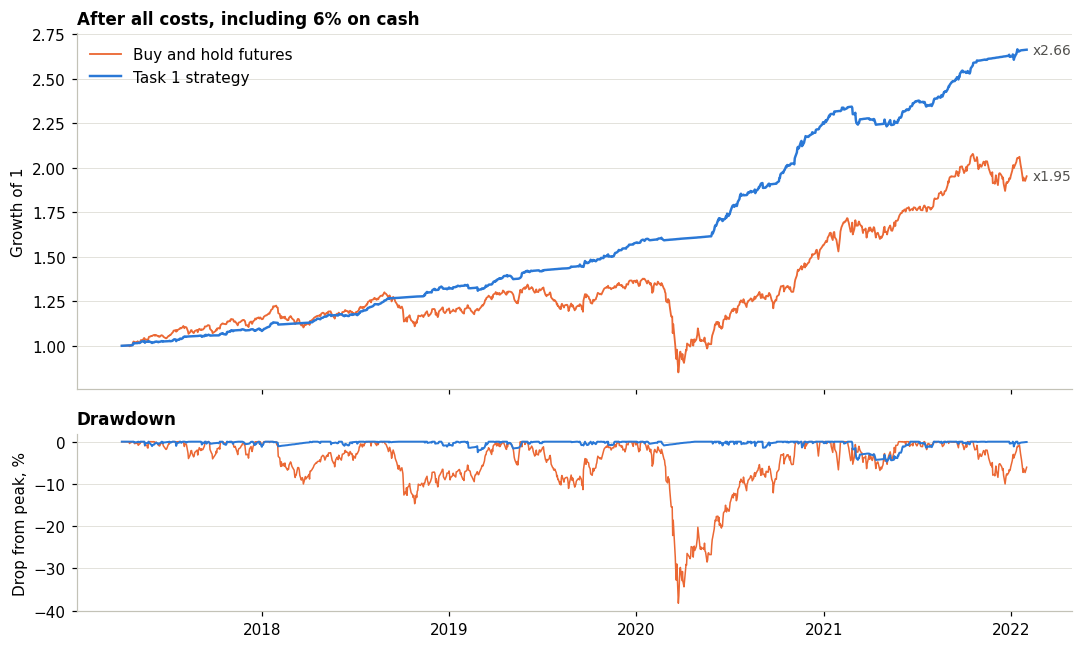

Strategy  Sharpe 2.95  worst loss -4.7%  yearly 22.5%
Buy&hold  Sharpe 0.53  worst loss -38.3%  yearly 14.9%


In [18]:
# %%
# 1.10 RESULT: The strategy against buy and hold, through the official harness.
want = T1.positions(bars, dict(P1)).values
res1 = H.task1_backtest(bars, want, ex)
s1, eq1 = H.task1_stats(res1)
bh = H.task1_backtest(bars, np.ones(len(bars)), ex)
sb, eqb = H.task1_stats(bh)
fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True, height_ratios=[2, 1])
ax[0].plot(eqb.index, eqb.values, color=ORANGE, lw=1.2, label='Buy and hold futures'); ax[0].plot(eq1.index, eq1.values, color=BLUE, lw=1.6, label='Task 1 strategy')
end_label(ax[0], eq1); end_label(ax[0], eqb); ax[0].legend(); ax[0].set_ylabel('Growth of 1'); ax[0].set_title('After all costs, including 6% on cash')
ax[1].plot(eqb.index, (eqb / eqb.cummax() - 1) * 100, color=ORANGE, lw=1); ax[1].plot(eq1.index, (eq1 / eq1.cummax() - 1) * 100, color=BLUE, lw=1.3)
ax[1].set_ylabel('Drop from peak, %'); ax[1].set_title('Drawdown'); years_axis(ax[1])
plt.tight_layout(); plt.show()
print('Strategy  Sharpe %.2f  worst loss %.1f%%  yearly %.1f%%' % (s1['sharpe'], 100 * s1['max_dd'], 100 * s1['cagr']))
print('Buy&hold  Sharpe %.2f  worst loss %.1f%%  yearly %.1f%%' % (sb['sharpe'], 100 * sb['max_dd'], 100 * sb['cagr']))


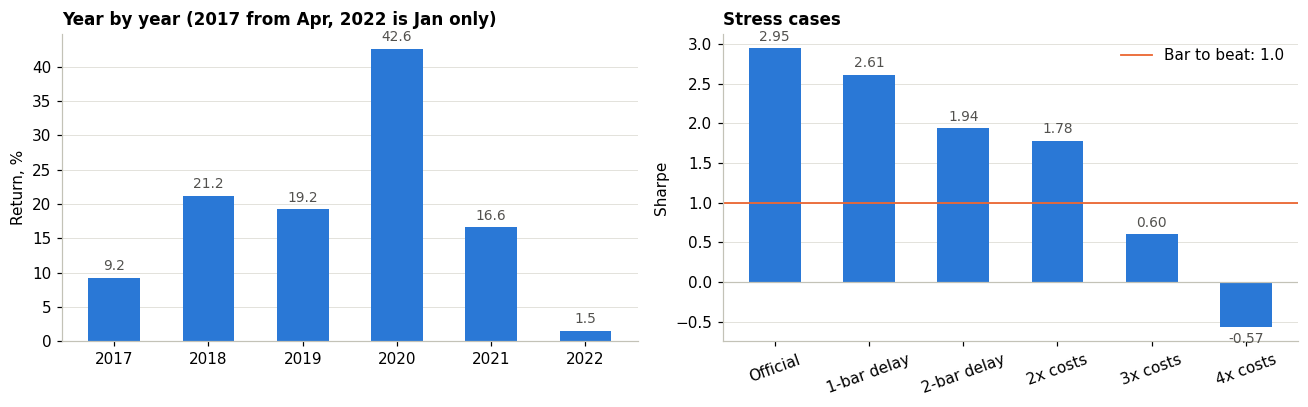

In [19]:
# %%
# 1.11 RESULT: Year by year, and the stress cases the brief asked for.
yr1 = pd.Series(s1['yearly']) * 100


def stressed(delay=0, cost=H.T1_COST):
    w = want if delay == 0 else np.r_[np.zeros(delay), want[:-delay]]
    return H.task1_stats(H.task1_backtest(bars, w, ex, cost=cost))[0]['sharpe']


cases = {'Official': s1['sharpe'], '1-bar delay': stressed(1), '2-bar delay': stressed(2), '2x costs': stressed(cost=2 * H.T1_COST), '3x costs': stressed(cost=3 * H.T1_COST), '4x costs': stressed(cost=4 * H.T1_COST)}
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].bar(range(len(yr1)), yr1.values, .55, color=BLUE); bar_labels(ax[0], range(len(yr1)), yr1.values); ax[0].set_xticks(range(len(yr1))); ax[0].set_xticklabels(yr1.index)
ax[0].set_ylabel('Return, %'); ax[0].set_title('Year by year (2017 from Apr, 2022 is Jan only)')
v = list(cases.values())
ax[1].bar(range(len(v)), v, .55, color=BLUE); bar_labels(ax[1], range(len(v)), v, '%.2f'); ax[1].axhline(1, color=ORANGE, lw=1.2, label='Bar to beat: 1.0'); ax[1].axhline(0, color='#c3c2b7', lw=.8)
ax[1].set_xticks(range(len(v))); ax[1].set_xticklabels(cases.keys(), rotation=20); ax[1].set_ylabel('Sharpe'); ax[1].legend(); ax[1].set_title('Stress cases')
plt.tight_layout(); plt.show()

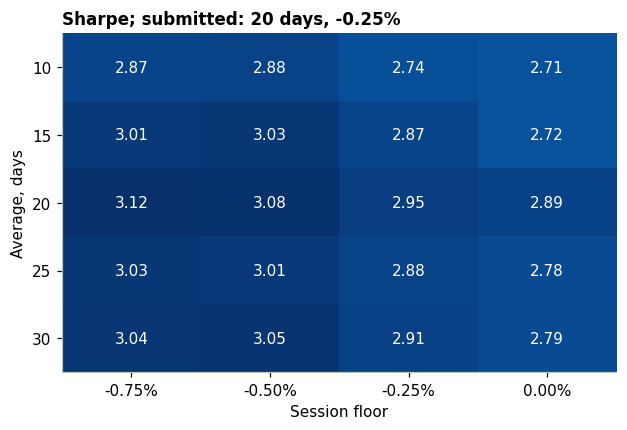

In [20]:
# %%
# 1.12 RESULT: Nearby settings all work, so the result does not rest on one exact choice.
mas, floors = [10, 15, 20, 25, 30], [-.0075, -.005, -.0025, 0.0]
grid = np.array([[H.task1_stats(H.task1_backtest(bars, T1.positions(bars, dict(P1, ma_days=m, session_floor=f)).values, ex))[0]['sharpe'] for f in floors] for m in mas])
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.imshow(grid, cmap='Blues', aspect='auto', vmin=0, vmax=grid.max()); ax.grid(False)
for i in range(len(mas)):
    for j in range(len(floors)):
        ax.text(j, i, '%.2f' % grid[i, j], ha='center', va='center', color='white' if grid[i, j] > .6 * grid.max() else '#0b0b0b')
ax.set_xticks(range(len(floors))); ax.set_xticklabels(['%.2f%%' % (100 * f) for f in floors]); ax.set_yticks(range(len(mas))); ax.set_yticklabels(mas)
ax.set_xlabel('Session floor'); ax.set_ylabel('Average, days'); ax.set_title('Sharpe; submitted: 20 days, -0.25%')
plt.show()

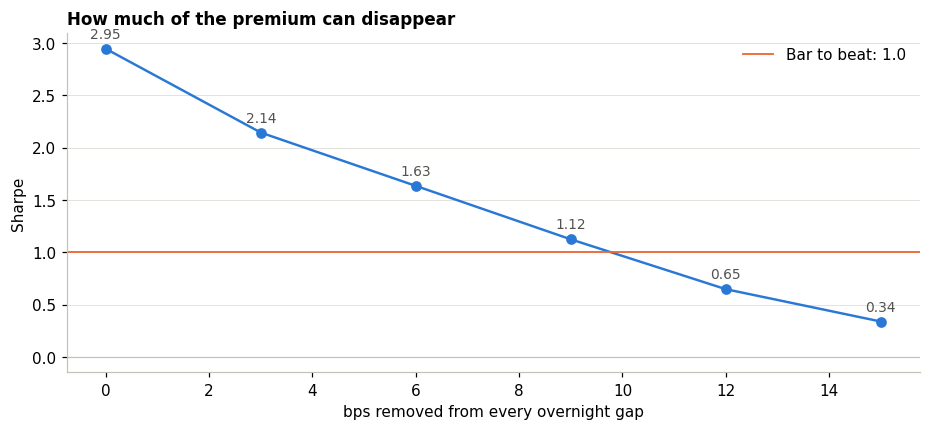

In [21]:
# %%
# 1.13 WHAT WOULD BREAK IT: Remove a fixed amount from every overnight gap, on the real in-sample data.
# Note: Feb 2022 to Jun 2024 breaks sooner: its gaps average about 9.4 bps, against 15.6 bps here.
cuts = [0, 3, 6, 9, 12, 15]
out = []
for x_ in cuts:
    f = (1 - x_ / 1e4) ** day_id
    b_ = bars.copy()
    for col in ['open', 'high', 'low', 'close']:
        b_[col] = bars[col].values * f
    out.append(H.task1_stats(H.task1_backtest(b_, T1.positions(b_, dict(P1)).values, ex))[0]['sharpe'])
fig, ax = plt.subplots()
ax.plot(cuts, out, color=BLUE, lw=1.6, marker='o', ms=6); ax.axhline(1, color=ORANGE, lw=1.2, label='Bar to beat: 1.0'); ax.axhline(0, color='#c3c2b7', lw=.8)
for a_, b_ in zip(cuts, out):
    ax.annotate('%.2f' % b_, (a_, b_), xytext=(0, 7), textcoords='offset points', ha='center', fontsize=9, color='#52514e')
ax.set_xlabel('bps removed from every overnight gap'); ax.set_ylabel('Sharpe'); ax.legend(); ax.set_title('How much of the premium can disappear')
plt.show()

In [22]:
# %%
# =========================================================================================================
# TASK 2: NSE STOCKS
# =========================================================================================================
# 2.0 LOAD
D = H.load_stocks([STOCK_CSV], [NIFTY_CSV])
C, O, Hi, Lo, V = D['close'], D['open'], D['high'], D['low'], D['volume']
N = D['nifty']['close']
ret = C.pct_change(fill_method=None)
clean = ret.where((ret.abs() < T2.JUMP) | ret.isna(), 0.0)
P = (1 + clean.fillna(0)).cumprod().where(C.notna())
TV = C * V
med = TV.rolling(60, min_periods=40).median()
EVAL = C.loc['2022-03-02':].index
ew_all = ret.loc[EVAL].mean(axis=1)
ew_liq = clean.where(med.shift(1) >= 1e8).loc[EVAL].mean(axis=1)
print(C.shape[1], 'symbols,', C.shape[0], 'days,', len(EVAL), 'days in the evaluation window')


555 symbols, 790 days, 577 days in the evaluation window


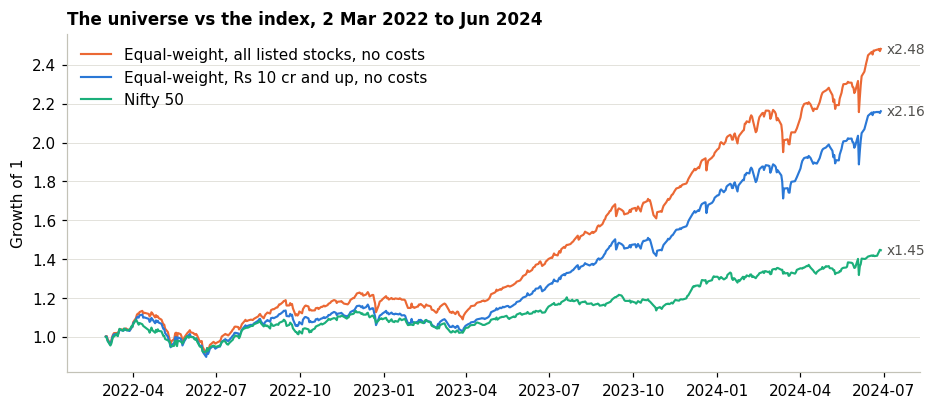

Sharpe: all 2.48 | liquid 2.08 | Nifty 1.26
Names still trading on the last date: 555 of 555


In [23]:
# %%
# 2.1 INSIGHT: The whole universe beat the index, before any stock selection. This is survivorship plus a bull market.
ga, gl, gn = (1 + ew_all).cumprod(), (1 + ew_liq).cumprod(), N.loc[EVAL] / N.loc[EVAL].iloc[0]
fig, ax = plt.subplots()
ax.plot(ga.index, ga.values, color=ORANGE, lw=1.4, label='Equal-weight, all listed stocks, no costs')
ax.plot(gl.index, gl.values, color=BLUE, lw=1.4, label='Equal-weight, Rs 10 cr and up, no costs')
ax.plot(gn.index, gn.values, color=AQUA, lw=1.4, label='Nifty 50')
for s in [ga, gl, gn]:
    end_label(ax, s)
ax.legend(); ax.set_ylabel('Growth of 1'); ax.set_title('The universe vs the index, 2 Mar 2022 to Jun 2024')
plt.show()
print('Sharpe: all %.2f | liquid %.2f | Nifty %.2f' % (perf(ew_all)['sharpe'], perf(ew_liq)['sharpe'], perf(N.loc[EVAL].pct_change().dropna())['sharpe']))
print('Names still trading on the last date: %d of %d' % (C.iloc[-1].notna().sum(), C.shape[1]))


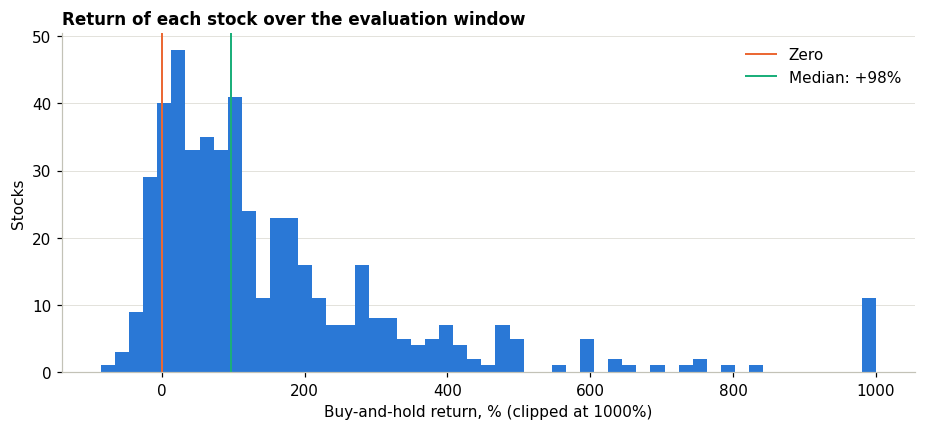

Fell: 11.4% | doubled: 49.0% | at least 5x: 9.6%
Best: {'TITAGARH': 2069.0, 'TARIL': 1959.0, 'MAZDOCK': 1632.0, 'JWL': 1621.0, 'GVT&D': 1615.0}
Worst: {'IBULLSLTD': -85.0, 'ADANIENSOL': -55.0, 'TATVA': -50.0, 'PAYTM': -50.0, 'GLAND': -44.0}


In [24]:
# %%
# 2.2 INSIGHT: Very few stocks fell. Part of this is the bull market, and part is that failed stocks are missing from the list.
hold = (C.iloc[-1] / C.loc['2022-03-02'] - 1).dropna() * 100
fig, ax = plt.subplots()
ax.hist(hold.clip(-100, 1000), bins=55, color=BLUE); ax.axvline(0, color=ORANGE, lw=1.3, label='Zero'); ax.axvline(hold.median(), color=AQUA, lw=1.3, label='Median: +%.0f%%' % hold.median())
ax.set_xlabel('Buy-and-hold return, % (clipped at 1000%)'); ax.set_ylabel('Stocks'); ax.legend(); ax.set_title('Return of each stock over the evaluation window')
plt.show()
print('Fell: %.1f%% | doubled: %.1f%% | at least 5x: %.1f%%' % ((hold < 0).mean() * 100, (hold >= 100).mean() * 100, (hold >= 400).mean() * 100))
print('Best:', hold.nlargest(5).round(0).to_dict()); print('Worst:', hold.nsmallest(5).round(0).to_dict())


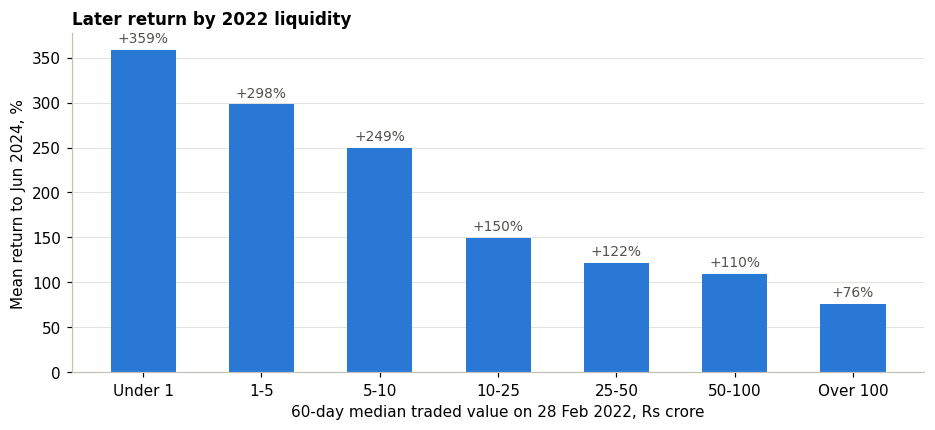

          names   mean  fell
b                           
Under 1      22  359.1   0.0
1-5          79  298.0   3.8
5-10         70  249.3  11.4
10-25        86  149.5  14.0
25-50        61  122.0  14.8
50-100       66  109.7  10.6
Over 100    104   76.0  15.4


In [25]:
# %%
# 2.3 INSIGHT: The less liquid a stock was in 2022, the more it later rose. It is on the 2026 list only because something big happened.
tv0 = med.loc['2022-02-28']
labs = ['Under 1', '1-5', '5-10', '10-25', '25-50', '50-100', 'Over 100']
bk = pd.cut(tv0, [0, 1e7, 5e7, 1e8, 2.5e8, 5e8, 1e9, 1e13], labels=labs)
tab2 = pd.DataFrame({'b': bk, 'r': hold}).dropna().groupby('b', observed=True).r.agg(['count', 'mean', lambda v: (v < 0).mean() * 100])
tab2.columns = ['names', 'mean', 'fell']
fig, ax = plt.subplots()
ax.bar(range(len(tab2)), tab2['mean'], .55, color=BLUE); bar_labels(ax, range(len(tab2)), tab2['mean'], '+%.0f%%')
ax.set_xticks(range(len(tab2))); ax.set_xticklabels(labs); ax.set_xlabel('60-day median traded value on 28 Feb 2022, Rs crore'); ax.set_ylabel('Mean return to Jun 2024, %')
ax.set_title('Later return by 2022 liquidity')
plt.show()
print(tab2.round(1).to_string())


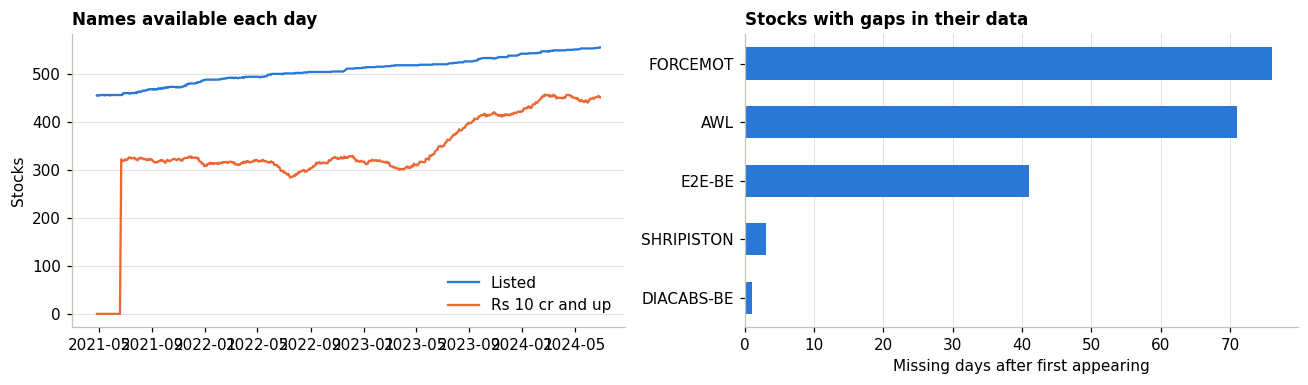

In [26]:
# %%
# 2.4 INSIGHT: The universe keeps growing, and a fixed rupee floor gets easier to pass.
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(C.index, C.notna().sum(axis=1), color=BLUE, lw=1.5, label='Listed'); ax[0].plot(C.index, (med >= 1e8).sum(axis=1), color=ORANGE, lw=1.5, label='Rs 10 cr and up')
ax[0].legend(); ax[0].set_ylabel('Stocks'); ax[0].set_title('Names available each day')
holes = {s: int(C[s].loc[C[s].first_valid_index():].isna().sum()) for s in C.columns}
hs = pd.Series({k: v for k, v in holes.items() if v > 0}).sort_values()
ax[1].barh(hs.index, hs.values, .55, color=BLUE); ax[1].grid(axis='x', color='#e1e0d9'); ax[1].grid(axis='y', visible=False); ax[1].set_xlabel('Missing days after first appearing'); ax[1].set_title('Stocks with gaps in their data')
plt.tight_layout(); plt.show()

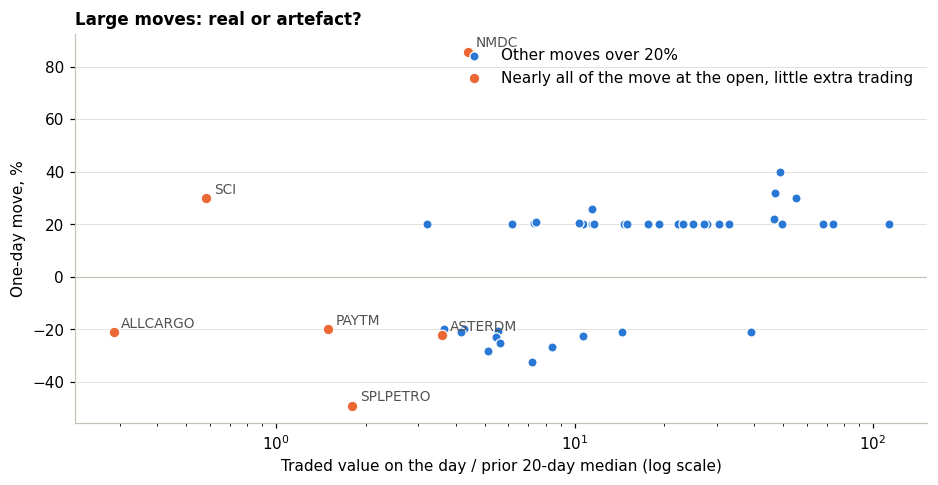

Typical move over 20% traded 11.6x normal
      date   symbol  move  at_open  tv_x
2022-06-07 SPLPETRO -49.1    -47.3   1.8
2022-10-27     NMDC  85.7     63.8   4.4
2023-03-31      SCI  30.0     30.0   0.6
2023-04-18 ALLCARGO -21.0    -24.8   0.3
2024-02-02    PAYTM -20.0    -20.0   1.5
2024-04-23  ASTERDM -22.2    -22.7   3.6


In [27]:
# %%
# 2.5 INSIGHT: Real jumps come with heavy trading. Artefacts do not: they sit lower and left on this chart.
base = TV.shift(1).rolling(20, min_periods=10).median()
rows = []
for i, j in zip(*np.where(np.abs(ret.values) > .20)):
    d_, s_ = C.index[i], C.columns[j]
    rows.append(dict(date=d_, symbol=s_, move=ret.values[i, j] * 100, at_open=(O.iloc[i, j] / C.iloc[i - 1, j] - 1) * 100, tv_x=TV.iloc[i, j] / base.iloc[i, j]))
jumps = pd.DataFrame(rows).dropna(subset=['tv_x'])
flagged = ['ALLCARGO', 'SCI', 'SPLPETRO', 'ASTERDM', 'NMDC', 'PAYTM']
isf = jumps.symbol.isin(flagged) & ((jumps.at_open / jumps.move) > .7)
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.scatter(jumps.tv_x[~isf], jumps.move[~isf], s=36, color=BLUE, edgecolor='white', linewidth=.8, label='Other moves over 20%')
ax.scatter(jumps.tv_x[isf], jumps.move[isf], s=48, color=ORANGE, edgecolor='white', linewidth=.8, label='Nearly all of the move at the open, little extra trading')
for _, r_ in jumps[isf].iterrows():
    ax.annotate(r_.symbol, (r_.tv_x, r_.move), xytext=(5, 3), textcoords='offset points', fontsize=9, color='#52514e')
ax.set_xscale('log'); ax.axhline(0, color='#c3c2b7', lw=.8); ax.set_xlabel("Traded value on the day / prior 20-day median (log scale)"); ax.set_ylabel('One-day move, %'); ax.legend(loc='upper right'); ax.set_title('Large moves: real or artefact?')
plt.show()
print('Typical move over 20%% traded %.1fx normal' % jumps.tv_x.median())
print(jumps[isf].round(1).to_string(index=False))

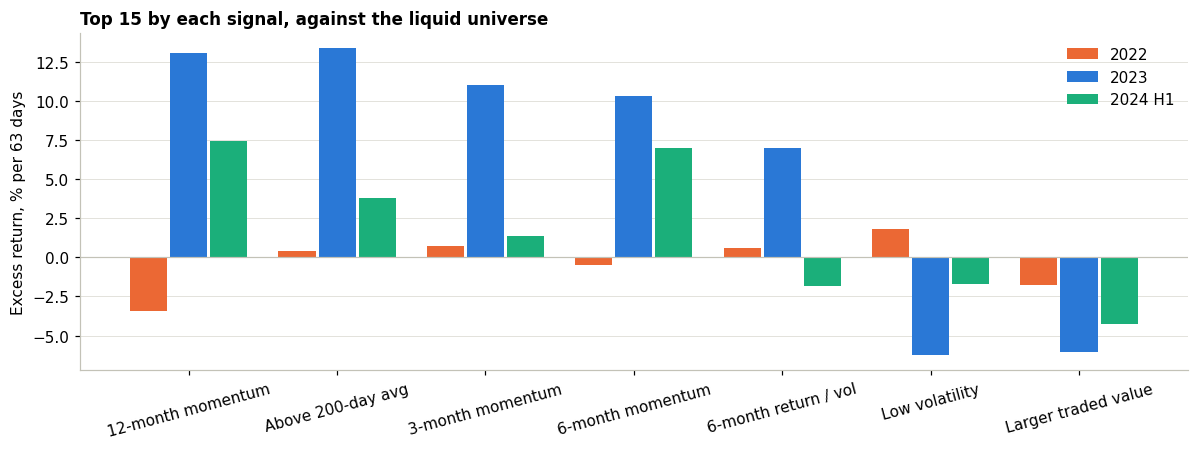

                      2022  2023  2024 H1
12-month momentum     -3.4  13.0      7.4
Above 200-day avg      0.4  13.3      3.8
3-month momentum       0.7  11.0      1.4
6-month momentum      -0.5  10.3      6.9
6-month return / vol   0.6   7.0     -1.8
Low volatility         1.8  -6.2     -1.7
Larger traded value   -1.7  -6.1     -4.3


In [28]:
# %%
# 2.6 INSIGHT: Which signals pick better stocks? Momentum depends on the market: absent in weak 2022, large in 2023.
# Top 15 by each signal, excess return over the liquid universe, % per 63 days. This cell takes a few seconds.
SIG = {'12-month momentum': P / P.shift(252) - 1, 'Above 200-day avg': P / P.rolling(200, min_periods=100).mean() - 1, '3-month momentum': P / P.shift(63) - 1, '6-month momentum': P / P.shift(126) - 1,
       '6-month return / vol': clean.rolling(126, min_periods=80).mean() / clean.rolling(126, min_periods=80).std(), 'Low volatility': -clean.rolling(120, min_periods=60).std(), 'Larger traded value': np.log(med)}
fwd = O.shift(-64) / O.shift(-1) - 1
fwd = fwd.where(fwd.abs() < 1.5)
PER = {'2022': ('2022-03-01', '2022-12-31'), '2023': ('2023-01-01', '2023-12-31'), '2024 H1': ('2024-01-01', '2024-06-30')}
res_sig = {}
for nm, f in SIG.items():
    res_sig[nm] = {}
    for pn, (a, z) in PER.items():
        v = []
        for d_ in C.loc[a:z].index[::5]:
            ok_ = (med.loc[d_] >= 1e8) & f.loc[d_].notna() & fwd.loc[d_].notna()
            if ok_.sum() >= 50:
                x_, y_ = f.loc[d_][ok_], fwd.loc[d_][ok_]
                v.append(y_[x_.nlargest(15).index].mean() - y_.mean())
        res_sig[nm][pn] = 100 * np.mean(v) if v else np.nan
tb = pd.DataFrame(res_sig).T
fig, ax = plt.subplots(figsize=(11, 4.2))
xx = np.arange(len(tb))
for i, (pn, col) in enumerate(zip(tb.columns, [ORANGE, BLUE, AQUA])):
    ax.bar(xx + (i - 1) * .27, tb[pn], .25, color=col, label=pn)
ax.axhline(0, color='#c3c2b7', lw=.8); ax.set_xticks(xx); ax.set_xticklabels(tb.index, rotation=15); ax.set_ylabel('Excess return, % per 63 days'); ax.legend(); ax.set_title('Top 15 by each signal, against the liquid universe')
plt.tight_layout(); plt.show()
print(tb.round(1).to_string())


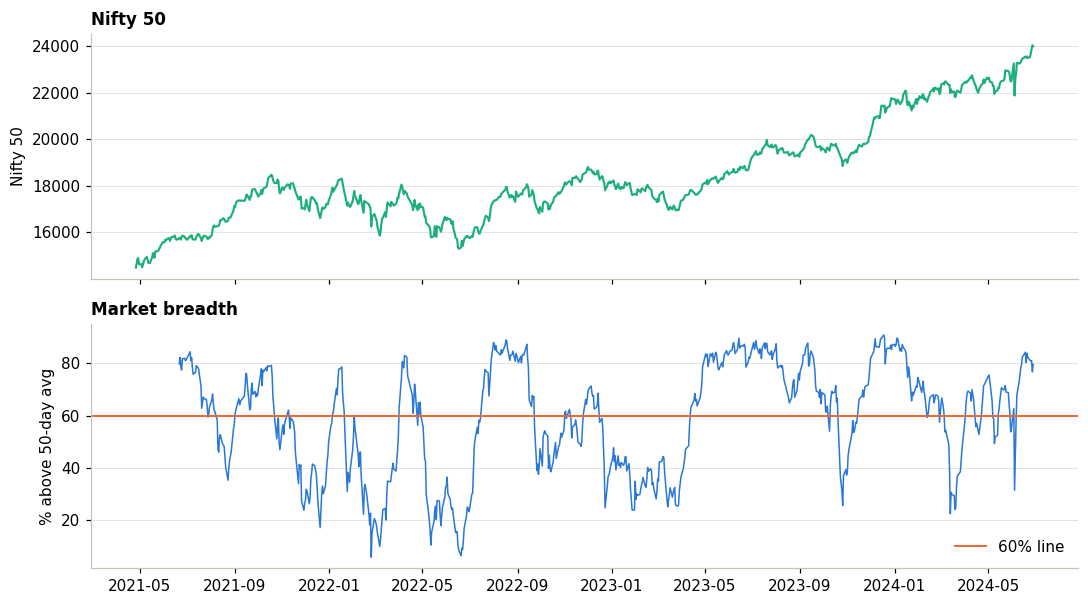

In [29]:
# %%
# 2.7 INSIGHT: Market breadth, the share of liquid stocks above their 50-day average. Under 60%, the strategy goes to cash.
above = (P > P.rolling(50, min_periods=30).mean()).astype(float).where(C.notna())
breadth = above.where(med >= 1e8).mean(axis=1)
fig, ax = plt.subplots(2, 1, figsize=(10, 5.6), sharex=True, height_ratios=[1, 1])
ax[0].plot(N.index, N.values, color=AQUA, lw=1.4); ax[0].set_ylabel('Nifty 50'); ax[0].set_title('Nifty 50')
ax[1].plot(breadth.index, breadth.values * 100, color=BLUE, lw=1); ax[1].axhline(60, color=ORANGE, lw=1.3, label='60% line')
ax[1].set_ylabel('% above 50-day avg'); ax[1].legend(loc='lower right'); ax[1].set_title('Market breadth')
plt.tight_layout(); plt.show()

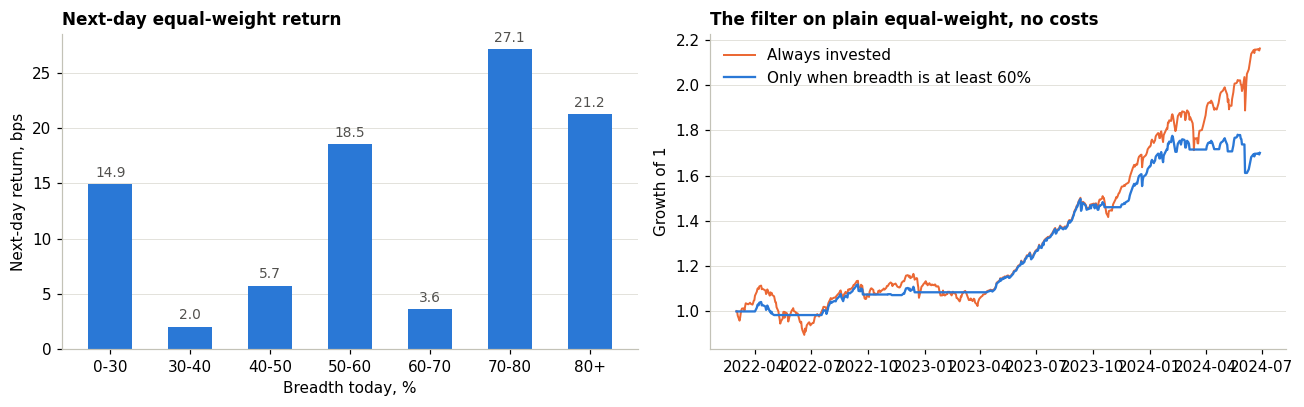

t-stats by bucket: {'0-30': 0.8, '30-40': 0.1, '40-50': 0.4, '50-60': 1.2, '60-70': 0.4, '70-80': 3.0, '80+': 3.4}
Always in: {'sharpe': np.float64(2.084), 'dd': -0.195, 'cagr': np.float64(0.4)} | Filtered: {'sharpe': np.float64(2.214), 'dd': -0.095, 'cagr': np.float64(0.261)}


In [30]:
# %%
# 2.8 INSIGHT: Only high breadth (over 70%) is followed by a statistically clear gain. On plain equal-weight stocks, the 60% filter mainly halves the worst loss.
nx = clean.where(med.shift(1) >= 1e8).mean(axis=1).shift(-1).loc[EVAL]
bins = [0, .3, .4, .5, .6, .7, .8, 1.0]; names = ['0-30', '30-40', '40-50', '50-60', '60-70', '70-80', '80+']
gb = nx.groupby(pd.cut(breadth.loc[EVAL], bins, labels=names), observed=True)
mb, tb2 = gb.mean() * 1e4, gb.mean() / gb.std() * gb.count() ** .5
on_ = (breadth.shift(1) >= .6).astype(float).loc[EVAL]
gated = ew_liq * on_
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].bar(range(len(mb)), mb.values, .55, color=BLUE); bar_labels(ax[0], range(len(mb)), mb.values); ax[0].set_xticks(range(len(mb))); ax[0].set_xticklabels(mb.index)
ax[0].set_xlabel('Breadth today, %'); ax[0].set_ylabel('Next-day return, bps'); ax[0].set_title('Next-day equal-weight return')
ax[1].plot(ew_liq.index, (1 + ew_liq).cumprod(), color=ORANGE, lw=1.3, label='Always invested'); ax[1].plot(gated.index, (1 + gated).cumprod(), color=BLUE, lw=1.5, label='Only when breadth is at least 60%')
ax[1].legend(); ax[1].set_ylabel('Growth of 1'); ax[1].set_title('The filter on plain equal-weight, no costs')
plt.tight_layout(); plt.show()
print('t-stats by bucket:', tb2.round(1).to_dict())
print('Always in:', {k: round(v, 3) for k, v in perf(ew_liq).items()}, '| Filtered:', {k: round(v, 3) for k, v in perf(gated).items()})


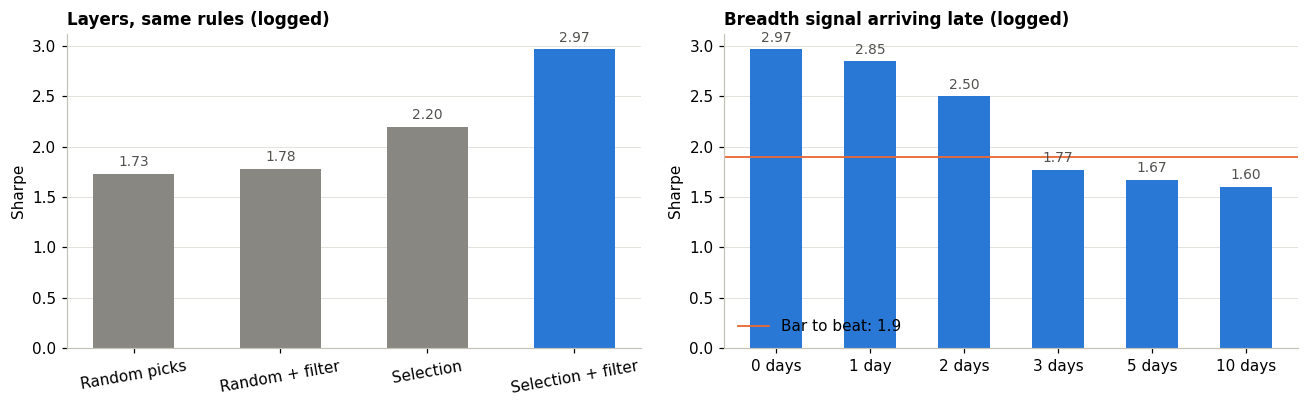

In [31]:
# %%
# 2.9 WHAT EACH LAYER ADDS, AND HOW FAST THE FILTER MUST REACT.
# These are logged results from the research runs, not computed here, because the random-pick runs take several minutes.
layers = {'Random picks': 1.73, 'Random + filter': 1.78, 'Selection': 2.20, 'Selection + filter': 2.97}
delay = {'0 days': 2.97, '1 day': 2.85, '2 days': 2.50, '3 days': 1.77, '5 days': 1.67, '10 days': 1.60}
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].bar(range(4), list(layers.values()), .55, color=[GREY, GREY, GREY, BLUE]); bar_labels(ax[0], range(4), list(layers.values()), '%.2f'); ax[0].set_xticks(range(4)); ax[0].set_xticklabels(layers.keys(), rotation=10)
ax[0].set_ylabel('Sharpe'); ax[0].set_title('Layers, same rules (logged)')
ax[1].bar(range(6), list(delay.values()), .55, color=BLUE); bar_labels(ax[1], range(6), list(delay.values()), '%.2f'); ax[1].axhline(1.9, color=ORANGE, lw=1.2, label='Bar to beat: 1.9'); ax[1].set_xticks(range(6)); ax[1].set_xticklabels(delay.keys())
ax[1].set_ylabel('Sharpe'); ax[1].legend(loc='lower left'); ax[1].set_title('Breadth signal arriving late (logged)')
plt.tight_layout(); plt.show()


Strategy  Sharpe 3.05  worst loss -11.2%  yearly 48.0%  trades 219  in market 50%


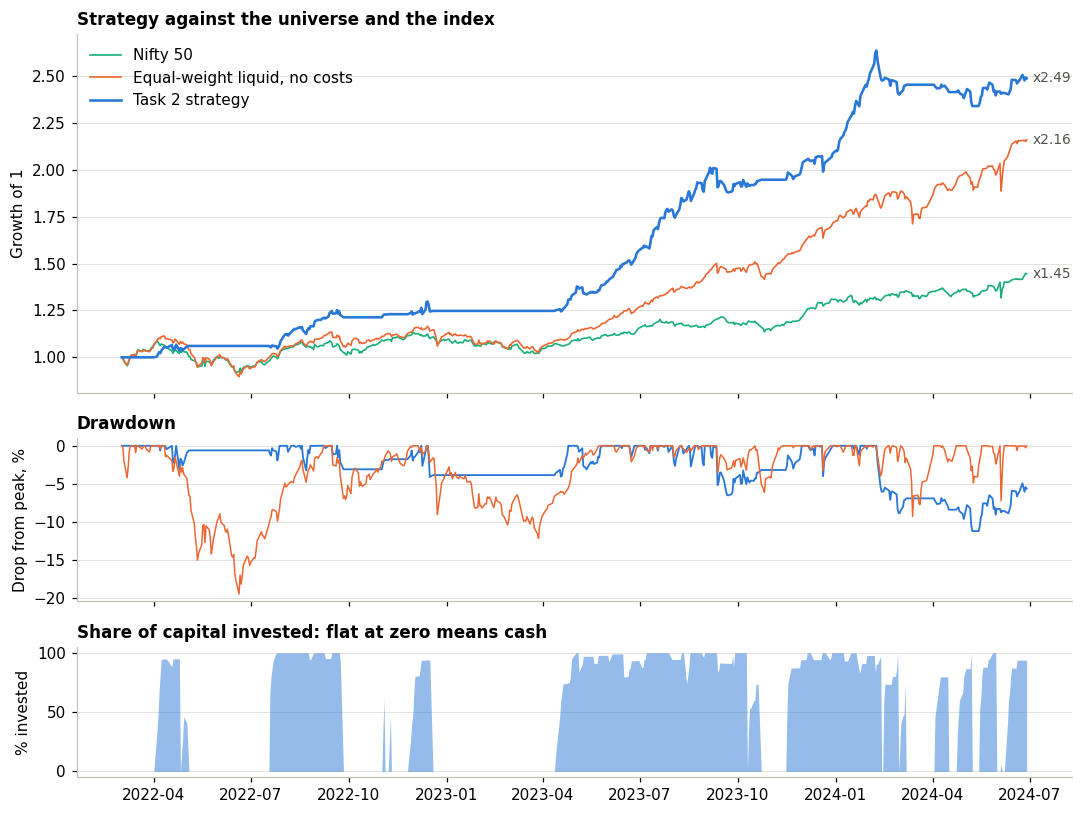

In [32]:
# %%
# 2.10 RESULT: The strategy through the official harness. Takes about 5 seconds.
res2 = H.task2_backtest(T2, D, dict(T2.PARAMS), H.T2_START, H.T2_END)
s2, eq2 = H.task2_stats(res2)
print('Strategy  Sharpe %.2f  worst loss %.1f%%  yearly %.1f%%  trades %d  in market %.0f%%' % (s2['sharpe'], 100 * s2['max_dd'], 100 * s2['cagr'], s2['trades'], 100 * s2['time_in_market']))
gl2, gn2 = gl.reindex(eq2.index), N.reindex(eq2.index) / N.reindex(eq2.index).iloc[0]
fig, ax = plt.subplots(3, 1, figsize=(10, 7.5), sharex=True, height_ratios=[2.2, 1, .8])
ax[0].plot(gn2.index, gn2.values, color=AQUA, lw=1.1, label='Nifty 50'); ax[0].plot(gl2.index, gl2.values, color=ORANGE, lw=1.1, label='Equal-weight liquid, no costs'); ax[0].plot(eq2.index, eq2.values, color=BLUE, lw=1.7, label='Task 2 strategy')
for s in [eq2, gl2, gn2]:
    end_label(ax[0], s)
ax[0].legend(); ax[0].set_ylabel('Growth of 1'); ax[0].set_title('Strategy against the universe and the index')
ax[1].plot(eq2.index, (eq2 / eq2.cummax() - 1) * 100, color=BLUE, lw=1.2); ax[1].plot(gl2.index, (gl2 / gl2.cummax() - 1) * 100, color=ORANGE, lw=1); ax[1].set_ylabel('Drop from peak, %'); ax[1].set_title('Drawdown')
ax[2].fill_between(res2['gross'].index, res2['gross'].values * 100, color=BLUE, alpha=.5, lw=0); ax[2].set_ylabel('% invested'); ax[2].set_title('Share of capital invested: flat at zero means cash')
plt.tight_layout(); plt.show()


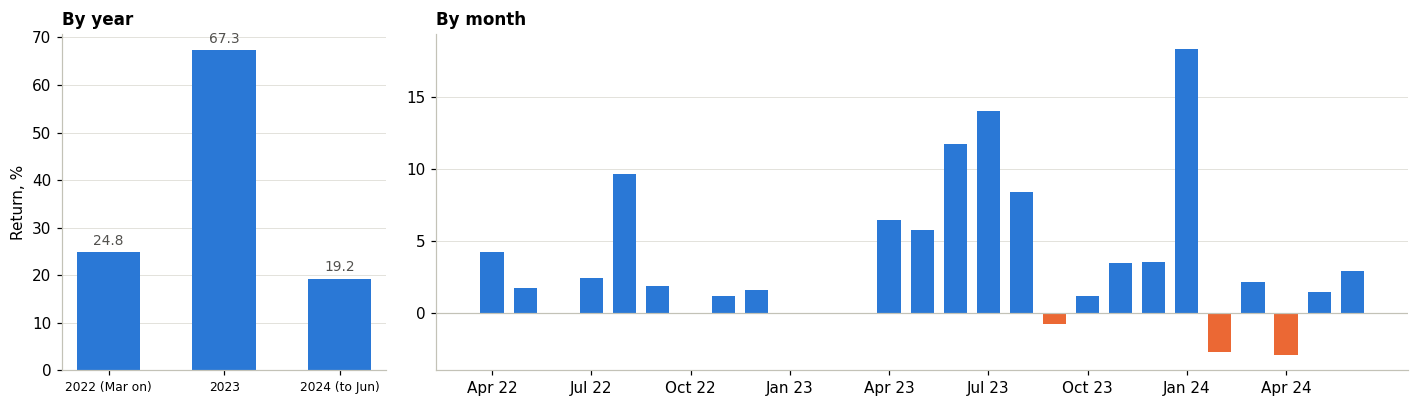

In [33]:
# %%
# 2.11 RESULT: Year by year and month by month.
yr2 = pd.Series(s2['yearly']) * 100
mo = eq2.resample('ME').last().pct_change().dropna() * 100
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), width_ratios=[1, 3])
ax[0].bar(range(len(yr2)), yr2.values, .55, color=BLUE); bar_labels(ax[0], range(len(yr2)), yr2.values); ax[0].set_xticks(range(len(yr2))); ax[0].set_xticklabels(['2022 (Mar on)', '2023', '2024 (to Jun)'], fontsize=8); ax[0].set_ylabel('Return, %'); ax[0].set_title('By year')
ax[1].bar(range(len(mo)), mo.values, .7, color=[BLUE if v >= 0 else ORANGE for v in mo.values]); ax[1].axhline(0, color='#c3c2b7', lw=.8); ax[1].set_xticks(range(0, len(mo), 3)); ax[1].set_xticklabels([mo.index[i].strftime('%b %y') for i in range(0, len(mo), 3)]); ax[1].set_title('By month')
plt.tight_layout(); plt.show()

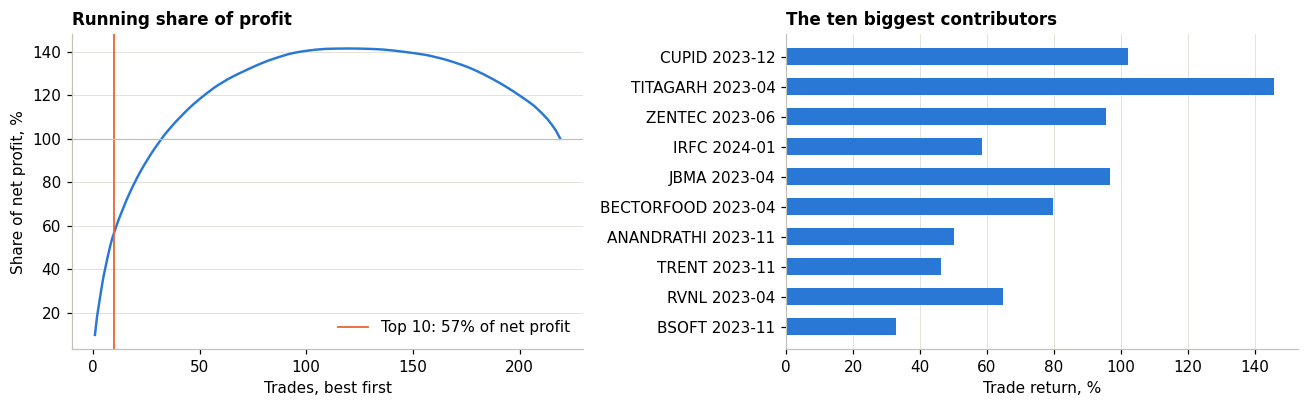

In [34]:
# %%
# 2.12 THE WEAKEST FEATURE: A few big winners make most of the profit.
Tr = res2['trades']
prev = eq2.shift(1).reindex(pd.to_datetime(Tr.entry_date)).fillna(1.0).values
Tr = Tr.assign(pnl=prev / T2.PARAMS['top_k'] * Tr.ret.values)
srt = Tr.sort_values('pnl', ascending=False)
share = srt.pnl.cumsum() / srt.pnl.sum() * 100
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(range(1, len(share) + 1), share.values, color=BLUE, lw=1.6); ax[0].axvline(10, color=ORANGE, lw=1.2, label='Top 10: %.0f%% of net profit' % share.iloc[9]); ax[0].axhline(100, color='#c3c2b7', lw=.8)
ax[0].set_xlabel('Trades, best first'); ax[0].set_ylabel('Share of net profit, %'); ax[0].legend(); ax[0].set_title('Running share of profit')
t10 = srt.head(10).iloc[::-1]
ax[1].barh(t10.symbol + ' ' + t10.entry_date.astype(str).str[:7], t10.ret * 100, .55, color=BLUE); ax[1].grid(axis='x', color='#e1e0d9'); ax[1].grid(axis='y', visible=False); ax[1].set_xlabel('Trade return, %'); ax[1].set_title('The ten biggest contributors')
plt.tight_layout(); plt.show()

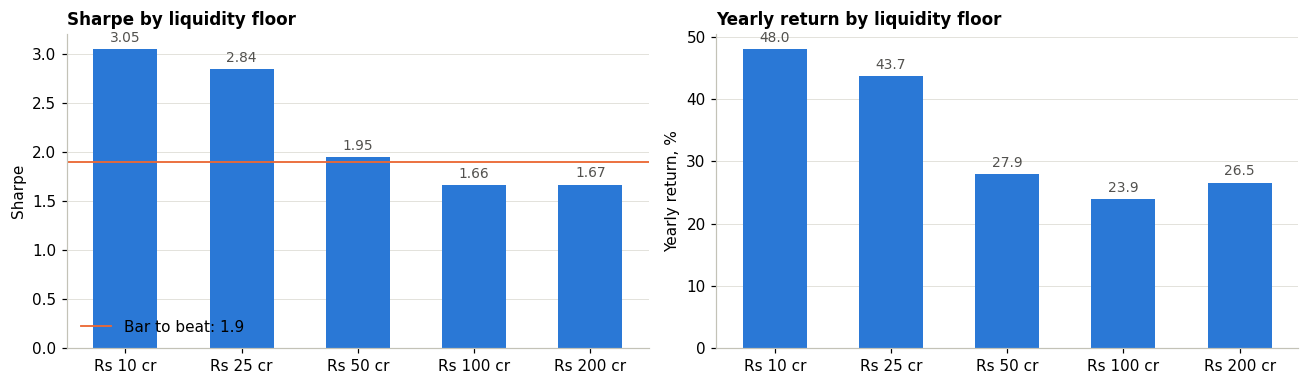

In [35]:
# %%
# 2.13 SURVIVORSHIP ON THE STRATEGY: Raising the liquidity floor removes the names most flattered by the bias. About 30 seconds.
# These use the official rebalance day, so they differ slightly from the report's means over 4 offsets.
keep = T2.MIN_TRADED_VALUE
rows = []
for fl in [1e8, 2.5e8, 5e8, 1e9, 2e9]:
    T2.MIN_TRADED_VALUE = fl
    s_, _ = H.task2_stats(H.task2_backtest(T2, D, dict(T2.PARAMS), H.T2_START, H.T2_END))
    rows.append((fl / 1e7, s_['sharpe'], s_['cagr'] * 100, s_['max_dd'] * 100))
T2.MIN_TRADED_VALUE = keep
fl_ = pd.DataFrame(rows, columns=['floor_cr', 'sharpe', 'cagr', 'dd'])
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
lb = ['Rs %.0f cr' % v for v in fl_.floor_cr]
ax[0].bar(range(5), fl_.sharpe, .55, color=BLUE); bar_labels(ax[0], range(5), fl_.sharpe, '%.2f'); ax[0].axhline(1.9, color=ORANGE, lw=1.2, label='Bar to beat: 1.9'); ax[0].set_xticks(range(5)); ax[0].set_xticklabels(lb); ax[0].set_ylabel('Sharpe'); ax[0].legend(loc='lower left'); ax[0].set_title('Sharpe by liquidity floor')
ax[1].bar(range(5), fl_.cagr, .55, color=BLUE); bar_labels(ax[1], range(5), fl_.cagr); ax[1].set_xticks(range(5)); ax[1].set_xticklabels(lb); ax[1].set_ylabel('Yearly return, %'); ax[1].set_title('Yearly return by liquidity floor')
plt.tight_layout(); plt.show()

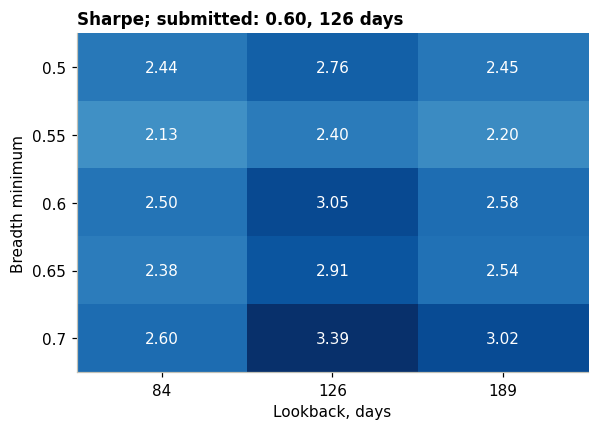

In [36]:
# %%
# 2.14 RESULT: Nearby settings. Takes about a minute. Neighbouring cells differ by chance, so read the overall level, not single cells.
# The 0.70 row looks best here, but it was rejected because it would rarely invest in a weaker market.
bms, lbs = [.5, .55, .6, .65, .7], [84, 126, 189]
gr2 = np.array([[H.task2_stats(H.task2_backtest(T2, D, dict(T2.PARAMS, breadth_min=b_, lookback=l_), H.T2_START, H.T2_END))[0]['sharpe'] for l_ in lbs] for b_ in bms])
fig, ax = plt.subplots(figsize=(6, 4))
ax.imshow(gr2, cmap='Blues', aspect='auto', vmin=0, vmax=gr2.max()); ax.grid(False)
for i in range(len(bms)):
    for j in range(len(lbs)):
        ax.text(j, i, '%.2f' % gr2[i, j], ha='center', va='center', color='white' if gr2[i, j] > .6 * gr2.max() else '#0b0b0b')
ax.set_xticks(range(len(lbs))); ax.set_xticklabels(lbs); ax.set_yticks(range(len(bms))); ax.set_yticklabels(bms); ax.set_xlabel('Lookback, days'); ax.set_ylabel('Breadth minimum'); ax.set_title('Sharpe; submitted: 0.60, 126 days')
plt.show()